In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "src" / "wesad" / "models.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục dự án.")

os.chdir(ROOT)

src_path = str(ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print("Project:", ROOT)
print("Python:", sys.executable)

Project: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection
Python: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\.venv\Scripts\python.exe


In [2]:
import pandas as pd
from IPython.display import display

from wesad.data import SUBJECTS, load_feature_table
from wesad.utils import read_config, file_hash


In [3]:
defaults = read_config(ROOT / "configs" / "defaults.yaml")

FEATURES = ROOT / defaults["features"]
SCHEMA = ROOT / defaults["schema"]

print("File dữ liệu:", FEATURES)
print("File schema:", SCHEMA)


File dữ liệu: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\data\features\g2_physiological68_group15_20261107\all_subjects.csv
File schema: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\data\features\g2_physiological68_group15_20261107\feature_schema.json


In [4]:
assert FEATURES.is_file(), f"Không tìm thấy dữ liệu: {FEATURES}"
assert SCHEMA.is_file(), f"Không tìm thấy schema: {SCHEMA}"

In [5]:
actual_sha = file_hash(FEATURES)
assert actual_sha == defaults["feature_sha256"], (
    f"Checksum không khớp. Giá trị hiện tại: {actual_sha}"
)


In [6]:
df, feature_columns = load_feature_table(
    FEATURES,
    SCHEMA,
    expected_subjects=SUBJECTS,
)

assert len(feature_columns) == 68, "Số đặc trưng khác 68."

print("\nĐã kiểm tra checksum và cấu trúc dữ liệu.")
print("Số cửa sổ:", len(df))
print("Số đặc trưng:", len(feature_columns))
print("Số người tham gia:", df["subject_id"].nunique())
print("Số giá trị thiếu trong các đặc trưng:",
      int(df[feature_columns].isna().sum().sum()))

print("\n5 dòng đầu:")
display(df.head())

print("\nSố cửa sổ theo người và nhãn:")
display(
    pd.crosstab(
        df["subject_id"],
        df["label_original"],
    ).reindex(SUBJECTS)
)


Đã kiểm tra checksum và cấu trúc dữ liệu.
Số cửa sổ: 6189
Số đặc trưng: 68
Số người tham gia: 15
Số giá trị thiếu trong các đặc trưng: 37460

5 dòng đầu:

Số cửa sổ theo người và nhãn:


,subject_id,window_id,start_s,end_s,label_original,label_binary,label_fraction,quality_flag,chest_ecg_hr_mean_bpm,chest_ecg_hr_std_bpm,chest_ecg_mean_rr_ms,chest_ecg_sd_rr_ms,chest_ecg_rmssd_ms,chest_ecg_pnn50,chest_ecg_power_5_10_hz,chest_ecg_power_10_20_hz,chest_ecg_power_20_40_hz,chest_eda_tonic_mean,chest_eda_tonic_std,chest_eda_phasic_mean,chest_eda_phasic_std,chest_eda_scr_count,chest_eda_scr_rate_per_min,chest_eda_scr_amplitude_mean,chest_eda_scr_amplitude_max,chest_resp_rate_mean,chest_resp_rate_std,chest_temp_mean,chest_temp_slope_per_s,chest_acc_x_5s_mean_mean,chest_acc_x_5s_std_mean,chest_acc_x_5s_abs_integral_mean,chest_acc_y_5s_mean_mean,chest_acc_y_5s_std_mean,chest_acc_y_5s_abs_integral_mean,chest_acc_z_5s_mean_mean,chest_acc_z_5s_std_mean,chest_acc_z_5s_abs_integral_mean,chest_acc_magnitude_5s_mean_mean,chest_acc_magnitude_5s_std_mean,chest_acc_magnitude_5s_abs_integral_mean,chest_emg_5s_rms_mean,chest_emg_5s_mav_mean,chest_emg_5s_waveform_length_per_s_mean,chest_emg_5s_abs_integral_mean,wrist_bvp_pulse_rate_mean_bpm,wrist_bvp_pulse_rate_std_bpm,wrist_bvp_mean_ibi_ms,wrist_bvp_sd_ibi_ms,wrist_bvp_rmssd_ibi_ms,wrist_bvp_pnn50_ibi,wrist_bvp_power_0p5_1_hz,wrist_bvp_power_1_2_hz,wrist_bvp_power_2_5_hz,wrist_eda_tonic_mean,wrist_eda_tonic_std,wrist_eda_phasic_mean,wrist_eda_phasic_std,wrist_eda_scr_count,wrist_eda_scr_rate_per_min,wrist_eda_scr_amplitude_mean,wrist_eda_scr_amplitude_max,wrist_temp_mean,wrist_temp_slope_per_s,wrist_acc_x_5s_mean_mean,wrist_acc_x_5s_std_mean,wrist_acc_x_5s_abs_integral_mean,wrist_acc_y_5s_mean_mean,wrist_acc_y_5s_std_mean,wrist_acc_y_5s_abs_integral_mean,wrist_acc_z_5s_mean_mean,wrist_acc_z_5s_std_mean,wrist_acc_z_5s_abs_integral_mean,wrist_acc_magnitude_5s_mean_mean,wrist_acc_magnitude_5s_std_mean,wrist_acc_magnitude_5s_abs_integral_mean
0,S2,S2_213500,305.0,365.0,1,0,0.974214,chest_temp:suspect_contact;wrist_bvp:insuffici...,84.815057,7.982102,714.008529,70.834865,45.355368,0.180328,0.005710,0.002311,0.000448,4.959958,0.279150,0.005540,0.058938,16.0,16.0,0.031461,0.114287,15.810293,3.863244,NaN,NaN,0.766066,0.026207,3.830332,-0.130370,0.022267,0.652165,-0.450157,0.072613,2.309938,0.940014,0.013319,4.700068,0.012352,0.009378,5.327183,0.046890,NaN,NaN,NaN,NaN,NaN,NaN,3512.933662,5887.985485,1972.740127,1.300075,0.136378,0.002940,0.075478,17.0,17.0,0.109529,0.276977,35.804500,-0.001071,0.523291,0.259505,2.881022,0.061051,0.145758,1.155599,0.590462,0.228952,3.180094,0.994083,0.077596,4.970416
1,S2,S2_217000,310.0,370.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,85.253561,7.835214,710.066964,69.232654,45.702536,0.175439,0.005820,0.002424,0.000463,4.876151,0.254922,-0.004305,0.022786,17.0,17.0,0.030696,0.114287,15.598766,4.276442,NaN,NaN,0.744148,0.025875,3.720740,-0.129814,0.021026,0.649388,-0.488150,0.071498,2.499902,0.942165,0.013045,4.710823,0.011351,0.008594,4.964009,0.042972,NaN,NaN,NaN,NaN,NaN,NaN,2877.326918,5319.913506,1812.396508,1.263621,0.121999,-0.002235,0.070433,16.0,16.0,0.113937,0.276977,35.798833,-0.001434,0.492074,0.248618,2.724935,0.079696,0.114213,1.072550,0.619442,0.221434,3.324992,0.993719,0.071203,4.968593
2,S2,S2_220500,315.0,375.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,82.243263,8.680372,737.946429,80.547557,50.444192,0.224138,0.005829,0.002398,0.000461,4.798716,0.239256,0.000644,0.014427,15.0,15.0,0.023950,0.059340,16.658299,4.575578,NaN,NaN,0.723083,0.025650,3.615416,-0.128232,0.020407,0.641477,-0.523262,0.070761,2.675463,0.944133,0.012946,4.720667,0.010518,0.007966,4.656417,0.039832,NaN,NaN,NaN,NaN,NaN,NaN,3207.434209,5779.629119,1867.849188,1.221529,0.098640,0.000555,0.069542,16.0,16.0,0.113937,0.276977,35.789833,-0.001804,0.464388,0.248850,2.586507,0.122770,0.113965,1.001139,0.642440,0.221584,3.439982,0.994281,0.071527,4.971405
3,S2,S2_224000,320.0,380.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,77.477849,9.297856,785.486542,93.293938,58.282859,0.307692,0.005988,0.002489,0.000462,4.728547,0.236

label_original,1,2,3
subject_id,,,
S2,219,113,63
S3,218,118,65
S4,222,117,65
S5,230,119,65
S6,226,121,65
S7,228,118,65
S8,224,124,64
S9,227,119,65
S10,226,135,65


In [7]:
df, feature_columns = load_feature_table(
    FEATURES,
    SCHEMA,
    expected_subjects=SUBJECTS,
)

assert len(feature_columns) == 68, "Số đặc trưng khác 68."

print("\nĐã kiểm tra checksum và cấu trúc dữ liệu.")
print("Số cửa sổ:", len(df))
print("Số đặc trưng:", len(feature_columns))
print("Số người tham gia:", df["subject_id"].nunique())
print("Số giá trị thiếu trong các đặc trưng:",
      int(df[feature_columns].isna().sum().sum()))

print("\n5 dòng đầu:")
display(df.head())

print("\nSố cửa sổ theo người và nhãn:")
display(
    pd.crosstab(
        df["subject_id"],
        df["label_original"],
    ).reindex(SUBJECTS)
)


Đã kiểm tra checksum và cấu trúc dữ liệu.
Số cửa sổ: 6189
Số đặc trưng: 68
Số người tham gia: 15
Số giá trị thiếu trong các đặc trưng: 37460

5 dòng đầu:

Số cửa sổ theo người và nhãn:


,subject_id,window_id,start_s,end_s,label_original,label_binary,label_fraction,quality_flag,chest_ecg_hr_mean_bpm,chest_ecg_hr_std_bpm,chest_ecg_mean_rr_ms,chest_ecg_sd_rr_ms,chest_ecg_rmssd_ms,chest_ecg_pnn50,chest_ecg_power_5_10_hz,chest_ecg_power_10_20_hz,chest_ecg_power_20_40_hz,chest_eda_tonic_mean,chest_eda_tonic_std,chest_eda_phasic_mean,chest_eda_phasic_std,chest_eda_scr_count,chest_eda_scr_rate_per_min,chest_eda_scr_amplitude_mean,chest_eda_scr_amplitude_max,chest_resp_rate_mean,chest_resp_rate_std,chest_temp_mean,chest_temp_slope_per_s,chest_acc_x_5s_mean_mean,chest_acc_x_5s_std_mean,chest_acc_x_5s_abs_integral_mean,chest_acc_y_5s_mean_mean,chest_acc_y_5s_std_mean,chest_acc_y_5s_abs_integral_mean,chest_acc_z_5s_mean_mean,chest_acc_z_5s_std_mean,chest_acc_z_5s_abs_integral_mean,chest_acc_magnitude_5s_mean_mean,chest_acc_magnitude_5s_std_mean,chest_acc_magnitude_5s_abs_integral_mean,chest_emg_5s_rms_mean,chest_emg_5s_mav_mean,chest_emg_5s_waveform_length_per_s_mean,chest_emg_5s_abs_integral_mean,wrist_bvp_pulse_rate_mean_bpm,wrist_bvp_pulse_rate_std_bpm,wrist_bvp_mean_ibi_ms,wrist_bvp_sd_ibi_ms,wrist_bvp_rmssd_ibi_ms,wrist_bvp_pnn50_ibi,wrist_bvp_power_0p5_1_hz,wrist_bvp_power_1_2_hz,wrist_bvp_power_2_5_hz,wrist_eda_tonic_mean,wrist_eda_tonic_std,wrist_eda_phasic_mean,wrist_eda_phasic_std,wrist_eda_scr_count,wrist_eda_scr_rate_per_min,wrist_eda_scr_amplitude_mean,wrist_eda_scr_amplitude_max,wrist_temp_mean,wrist_temp_slope_per_s,wrist_acc_x_5s_mean_mean,wrist_acc_x_5s_std_mean,wrist_acc_x_5s_abs_integral_mean,wrist_acc_y_5s_mean_mean,wrist_acc_y_5s_std_mean,wrist_acc_y_5s_abs_integral_mean,wrist_acc_z_5s_mean_mean,wrist_acc_z_5s_std_mean,wrist_acc_z_5s_abs_integral_mean,wrist_acc_magnitude_5s_mean_mean,wrist_acc_magnitude_5s_std_mean,wrist_acc_magnitude_5s_abs_integral_mean
0,S2,S2_213500,305.0,365.0,1,0,0.974214,chest_temp:suspect_contact;wrist_bvp:insuffici...,84.815057,7.982102,714.008529,70.834865,45.355368,0.180328,0.005710,0.002311,0.000448,4.959958,0.279150,0.005540,0.058938,16.0,16.0,0.031461,0.114287,15.810293,3.863244,NaN,NaN,0.766066,0.026207,3.830332,-0.130370,0.022267,0.652165,-0.450157,0.072613,2.309938,0.940014,0.013319,4.700068,0.012352,0.009378,5.327183,0.046890,NaN,NaN,NaN,NaN,NaN,NaN,3512.933662,5887.985485,1972.740127,1.300075,0.136378,0.002940,0.075478,17.0,17.0,0.109529,0.276977,35.804500,-0.001071,0.523291,0.259505,2.881022,0.061051,0.145758,1.155599,0.590462,0.228952,3.180094,0.994083,0.077596,4.970416
1,S2,S2_217000,310.0,370.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,85.253561,7.835214,710.066964,69.232654,45.702536,0.175439,0.005820,0.002424,0.000463,4.876151,0.254922,-0.004305,0.022786,17.0,17.0,0.030696,0.114287,15.598766,4.276442,NaN,NaN,0.744148,0.025875,3.720740,-0.129814,0.021026,0.649388,-0.488150,0.071498,2.499902,0.942165,0.013045,4.710823,0.011351,0.008594,4.964009,0.042972,NaN,NaN,NaN,NaN,NaN,NaN,2877.326918,5319.913506,1812.396508,1.263621,0.121999,-0.002235,0.070433,16.0,16.0,0.113937,0.276977,35.798833,-0.001434,0.492074,0.248618,2.724935,0.079696,0.114213,1.072550,0.619442,0.221434,3.324992,0.993719,0.071203,4.968593
2,S2,S2_220500,315.0,375.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,82.243263,8.680372,737.946429,80.547557,50.444192,0.224138,0.005829,0.002398,0.000461,4.798716,0.239256,0.000644,0.014427,15.0,15.0,0.023950,0.059340,16.658299,4.575578,NaN,NaN,0.723083,0.025650,3.615416,-0.128232,0.020407,0.641477,-0.523262,0.070761,2.675463,0.944133,0.012946,4.720667,0.010518,0.007966,4.656417,0.039832,NaN,NaN,NaN,NaN,NaN,NaN,3207.434209,5779.629119,1867.849188,1.221529,0.098640,0.000555,0.069542,16.0,16.0,0.113937,0.276977,35.789833,-0.001804,0.464388,0.248850,2.586507,0.122770,0.113965,1.001139,0.642440,0.221584,3.439982,0.994281,0.071527,4.971405
3,S2,S2_224000,320.0,380.0,1,0,1.000000,chest_temp:suspect_contact;wrist_bvp:insuffici...,77.477849,9.297856,785.486542,93.293938,58.282859,0.307692,0.005988,0.002489,0.000462,4.728547,0.236

label_original,1,2,3
subject_id,,,
S2,219,113,63
S3,218,118,65
S4,222,117,65
S5,230,119,65
S6,226,121,65
S7,228,118,65
S8,224,124,64
S9,227,119,65
S10,226,135,65


## R02 — Dummy baseline đủ 15 người

Mục tiêu: xác định mức đối chứng trên toàn bộ 15 người.

Giữ nguyên mô hình, dữ liệu và thiết lập của R01.
Mỗi fold train trên 14 người và test người còn lại.
Thực hiện hai bài toán multiclass và binary: tổng cộng 30 fold.

Giả thuyết: Dummy chỉ dự đoán lớp phổ biến nhất trong train,
nên không phân biệt được đầy đủ các trạng thái.

In [8]:
from copy import deepcopy
from wesad.evaluation import run_experiment

CONFIG_R02 = deepcopy(defaults)

CONFIG_R02.update({
    "protocol": "notebook_research_new_runs_v1",
    "experiment_id": "THAI-EXP-001",
    "group_experiment_id": "EXP-001",
    "run_no": "r02",
    "run_scope": "main",
    "models": ["dummy"],
    "tasks": ["multiclass", "binary"],
    "balance": False,
    "nested": False,
    "output_dir": "outputs/notebook_research/THAI-EXP-001/r02_main",
    "source_paths": [
        "src/wesad/data.py",
        "src/wesad/evaluation.py",
        "src/wesad/models.py",
        "src/wesad/utils.py",
    ],
})

RUN_DIR_R02 = ROOT / CONFIG_R02["output_dir"]

assert file_hash(FEATURES) == CONFIG_R02["feature_sha256"]

result_r02 = run_experiment(
    CONFIG_R02,
    resume=True,
    outer_subjects=None,
)

print("Trạng thái:", result_r02["status"])
print("Kết quả:", RUN_DIR_R02)

multiclass/dummy/S10: SKIP verified
multiclass/dummy/S11: SKIP verified
multiclass/dummy/S13: SKIP verified
multiclass/dummy/S14: SKIP verified
multiclass/dummy/S15: SKIP verified
multiclass/dummy/S16: SKIP verified
multiclass/dummy/S17: SKIP verified
multiclass/dummy/S2: SKIP verified
multiclass/dummy/S3: SKIP verified
multiclass/dummy/S4: SKIP verified
multiclass/dummy/S5: SKIP verified
multiclass/dummy/S6: SKIP verified
multiclass/dummy/S7: SKIP verified
multiclass/dummy/S8: SKIP verified
multiclass/dummy/S9: SKIP verified
binary/dummy/S10: SKIP verified
binary/dummy/S11: SKIP verified
binary/dummy/S13: SKIP verified
binary/dummy/S14: SKIP verified
binary/dummy/S15: SKIP verified
binary/dummy/S16: SKIP verified
binary/dummy/S17: SKIP verified
binary/dummy/S2: SKIP verified
binary/dummy/S3: SKIP verified
binary/dummy/S4: SKIP verified
binary/dummy/S5: SKIP verified
binary/dummy/S6: SKIP verified
binary/dummy/S7: SKIP verified
binary/dummy/S8: SKIP verified
binary/dummy/S9: SKIP verif

In [9]:
metrics_r02 = pd.read_csv(
    RUN_DIR_R02 / "metrics_by_subject.csv"
)



# Kiểm tra đủ 15 người × 2 bài toán.


In [10]:
assert result_r02["status"] == "complete"
assert len(metrics_r02) == 30
assert set(metrics_r02["model"]) == {"dummy"}
assert not metrics_r02.duplicated(
    ["task", "model", "subject_id"]
).any()

for task in ["multiclass", "binary"]:
    part = metrics_r02.loc[metrics_r02["task"].eq(task)]
    assert set(part["subject_id"]) == set(SUBJECTS)

print("PASS: đủ 30 fold, không trùng kết quả.")

display(metrics_r02)


PASS: đủ 30 fold, không trùng kết quả.


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,seconds
0,S10,multiclass,dummy,426,0.231084,0.333333,0.2125
1,S11,multiclass,dummy,417,0.234990,0.333333,0.0927
2,S13,multiclass,dummy,417,0.234318,0.333333,0.0986
3,S14,multiclass,dummy,410,0.232114,0.333333,0.0790
4,S15,multiclass,dummy,418,0.233954,0.333333,0.0832
5,S16,multiclass,dummy,415,0.235049,0.333333,0.0983
6,S17,multiclass,dummy,426,0.231084,0.333333,0.0924
7,S2,multiclass,dummy,395,0.237785,0.333333,0.0743
8,S3,multiclass,dummy,401,0.234787,0.333333,0.1121
9,S4,multiclass,dummy,404,0.236422,0.333333,0.0790



# Trung bình và độ lệch chuẩn giữa 15 người.


In [11]:
summary_r02 = metrics_r02.groupby("task")[
    ["macro_f1", "balanced_accuracy"]
].agg(["mean", "std"])

display(summary_r02)

macro_f1           balanced_accuracy     
                mean       std              mean  std
task                                                 
binary      0.412281  0.003526          0.500000  0.0
multiclass  0.235047  0.002305          0.333333  0.0

## Kết quả và nhận xét R02

Đã hoàn thành LOSO cho 15 người trên hai bài toán, tổng cộng 30 fold.

- Binary: Macro-F1 = 0.412281 ± 0.003526;
  Balanced Accuracy = 0.500000 ± 0.
- Multiclass: Macro-F1 = 0.235047 ± 0.002305;
  Balanced Accuracy = 0.333333 ± 0.

Các giá trị được tổng hợp bằng trung bình và độ lệch chuẩn
giữa 15 người.

Dummy chỉ dự đoán lớp phổ biến nhất trong train.
Balanced Accuracy bằng 1/2 ở binary và 1/3 ở multiclass
phù hợp với việc chỉ nhận diện được một lớp.

Macro-F1 thay đổi nhẹ giữa các người do tỷ lệ nhãn khác nhau.
Độ lệch chuẩn thấp ở đây không chứng minh mô hình nhận diện tốt.

Kết quả này được dùng làm đối chứng cho các mô hình tiếp theo.

## Quyết định tiếp theo

Thực hiện THAI-EXP-002 — Logistic Regression, giữ nguyên dữ liệu
và cách đánh giá để so sánh với Dummy.

## Biểu đồ kết quả


Ảnh được lưu tại: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\outputs\notebook_research\THAI-EXP-001\r02_main\figures
Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.
Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.


macro_f1           balanced_accuracy     
                mean       std              mean  std
task                                                 
binary      0.412281  0.003526          0.500000  0.0
multiclass  0.235047  0.002305          0.333333  0.0

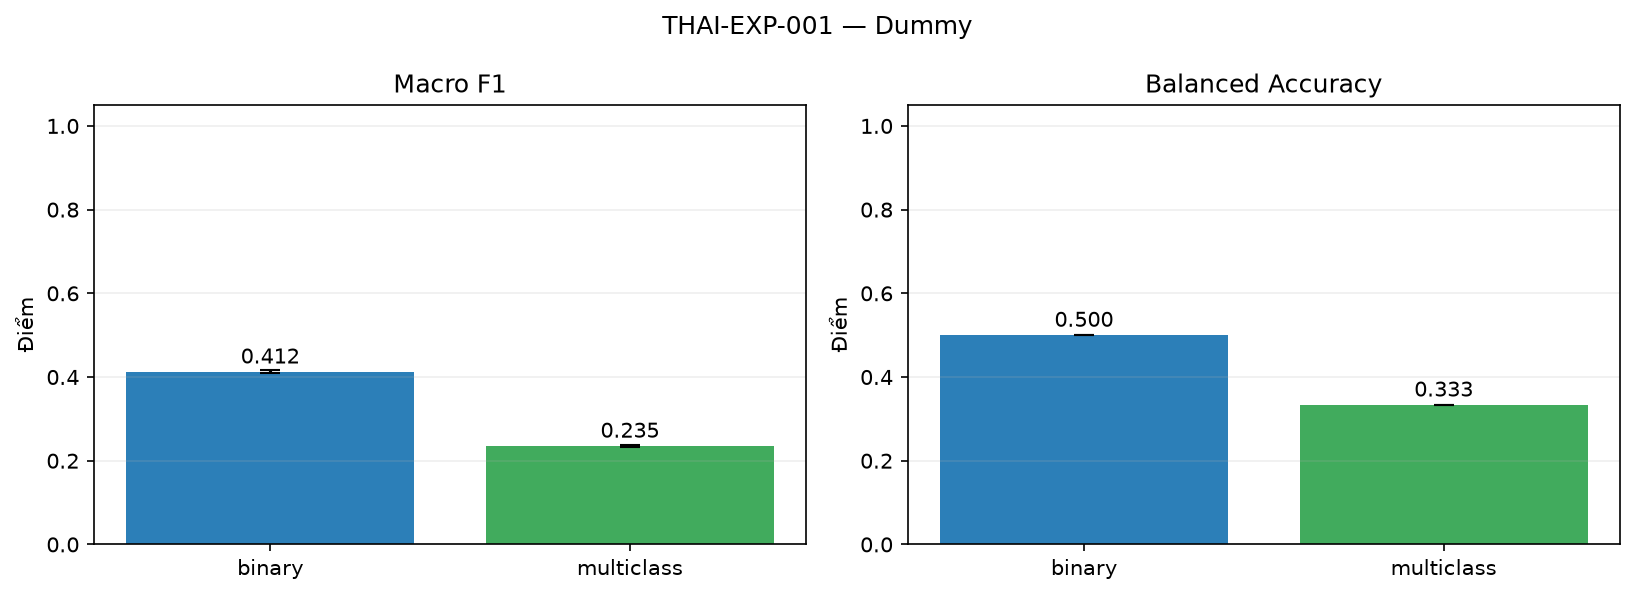

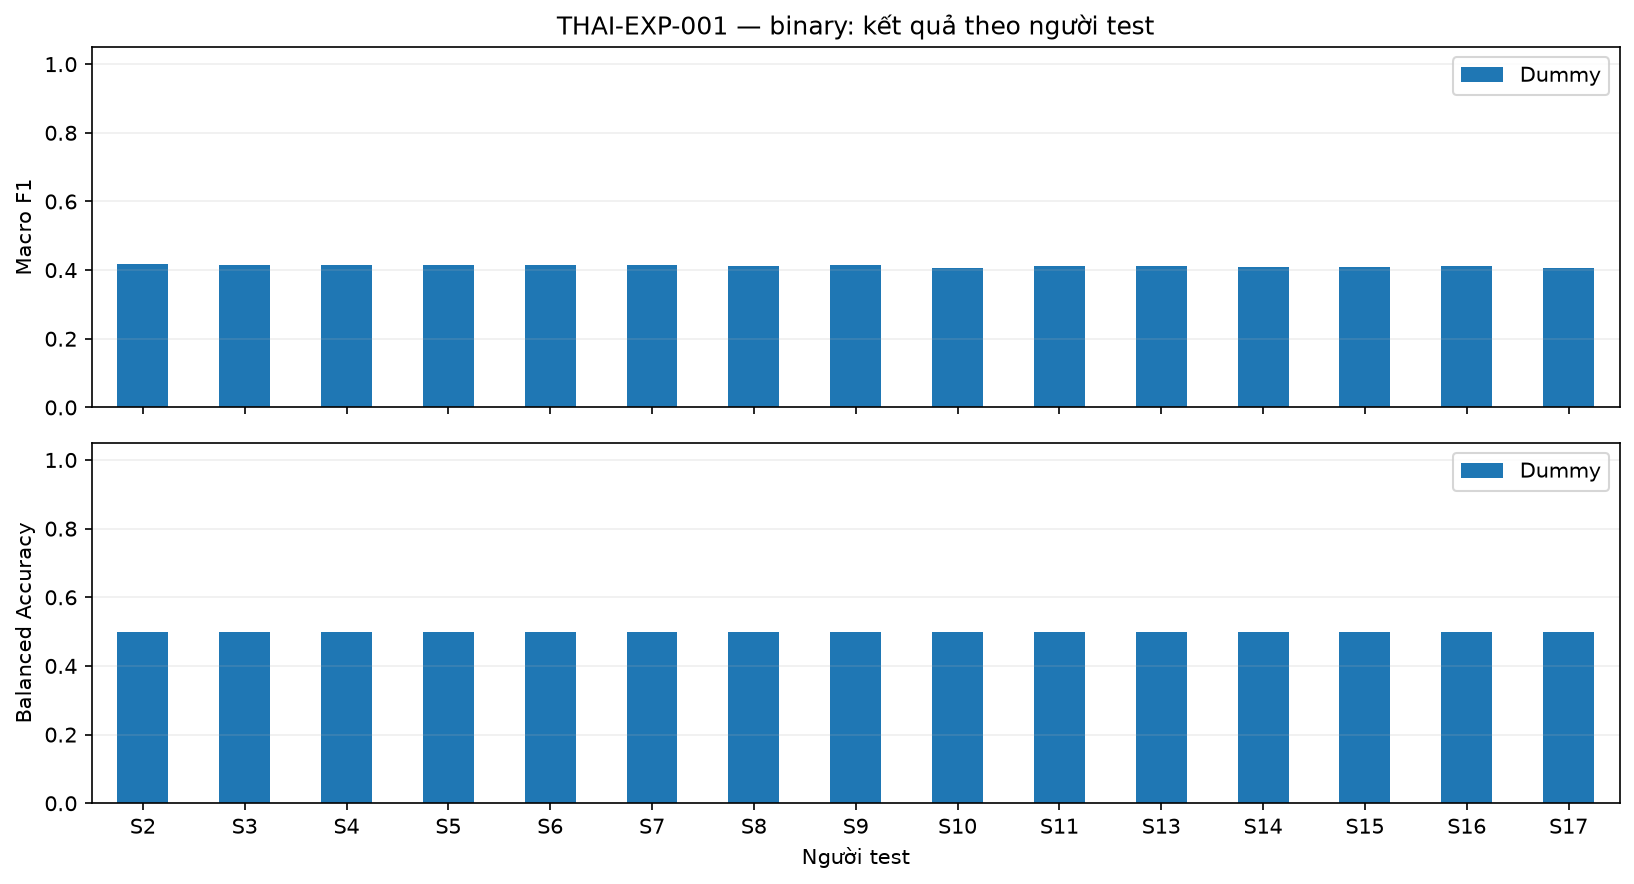

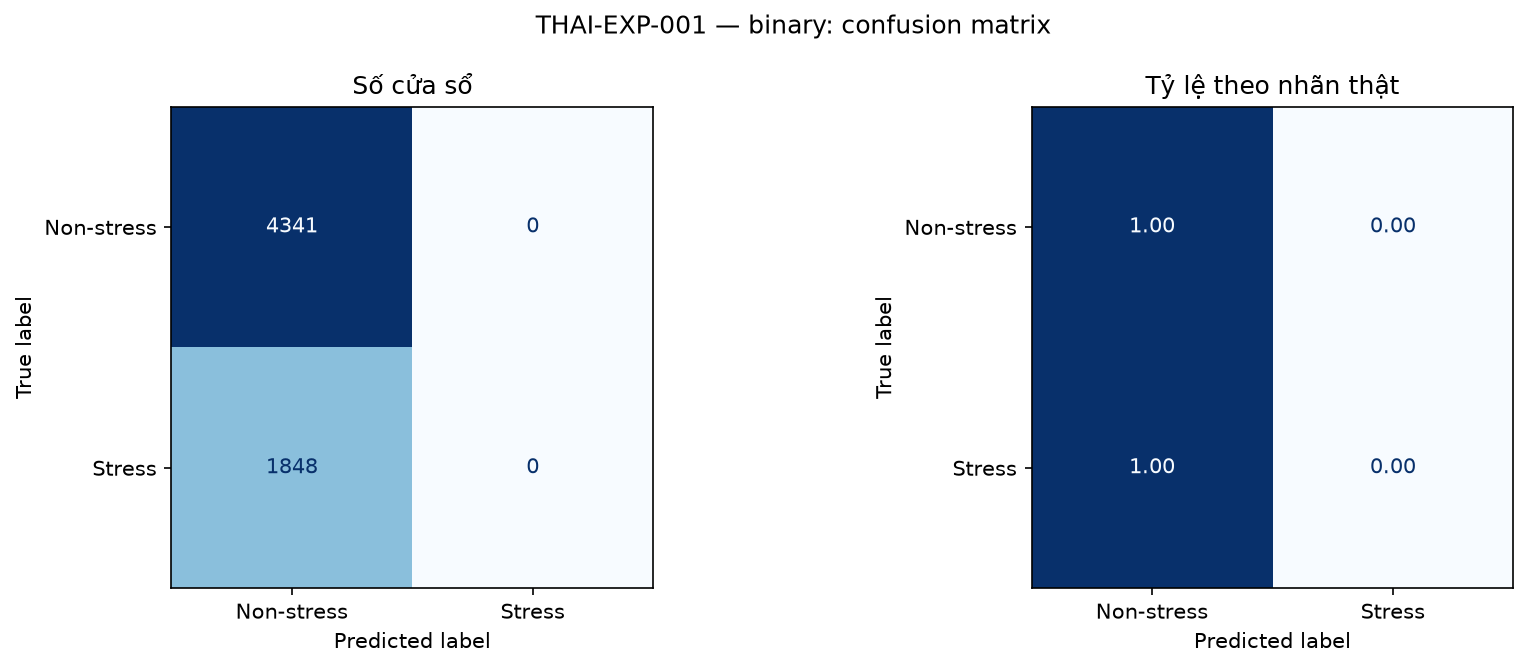

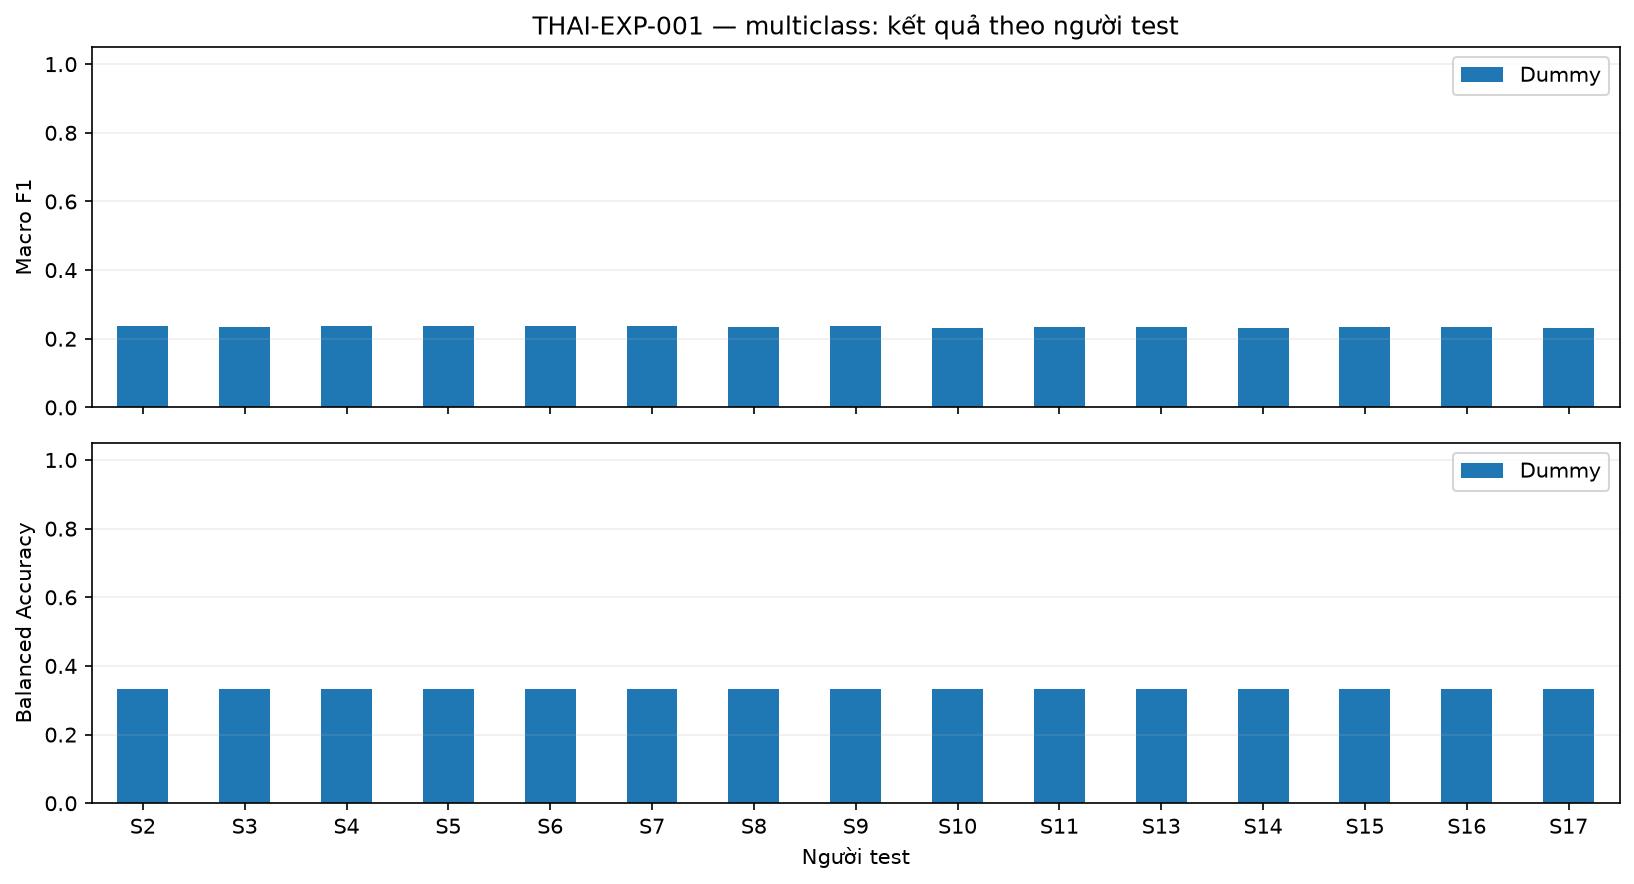

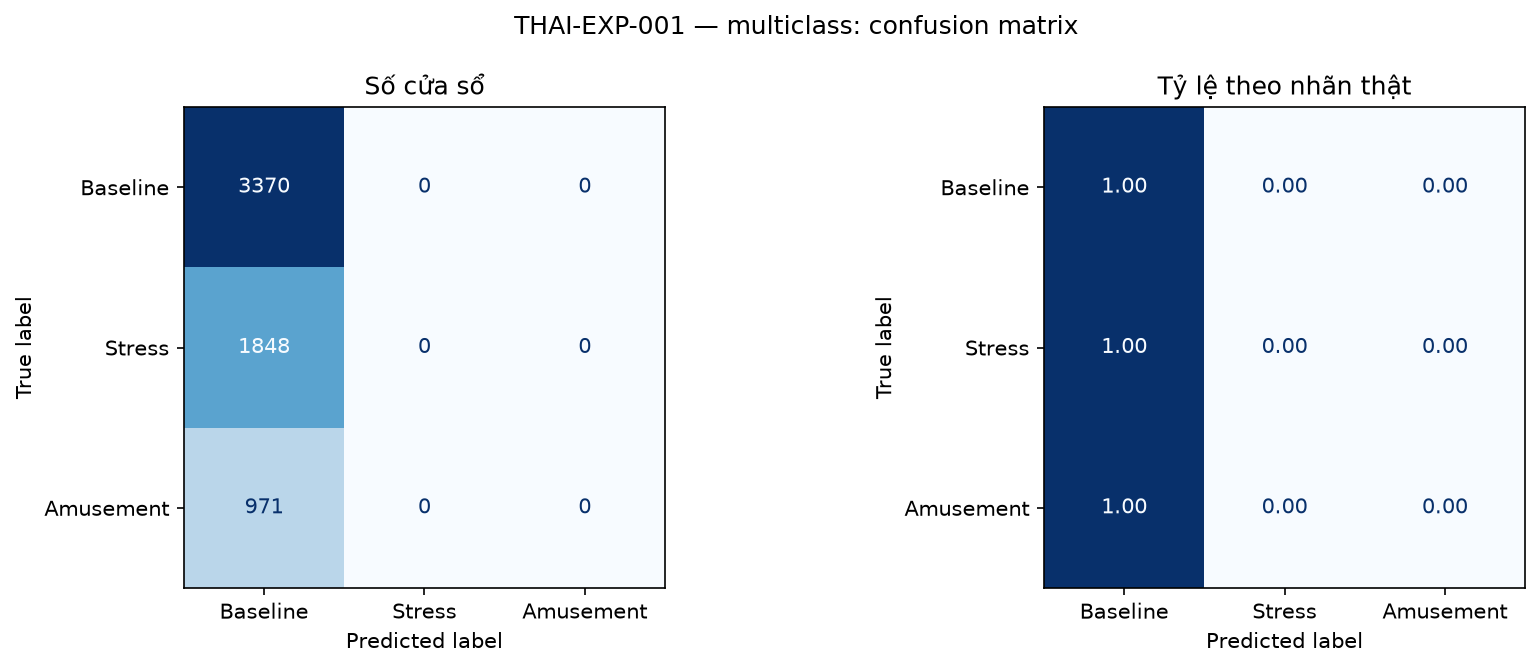

In [12]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook trong thư mục dự án.")

RUN_DIR_VIS = ROOT / "outputs/notebook_research/THAI-EXP-001/r02_main"
REFERENCE_VIS = None
MODEL_LABEL = "Dummy"
REFERENCE_LABEL = ""
FIGURES_VIS = RUN_DIR_VIS / "figures"

for name in ["metrics_by_subject.csv", "predictions.csv"]:
    if not (RUN_DIR_VIS / name).is_file():
        raise FileNotFoundError(f"Thiếu kết quả: {RUN_DIR_VIS / name}")

metrics_vis = pd.read_csv(RUN_DIR_VIS / "metrics_by_subject.csv")
predictions_vis = pd.read_csv(RUN_DIR_VIS / "predictions.csv")
assert not metrics_vis.duplicated(["task", "model", "subject_id"]).any()
assert not predictions_vis.duplicated(["task", "model", "subject_id", "window_id"]).any()
assert metrics_vis.model.nunique() == 1
reference_vis = None
if REFERENCE_VIS is not None:
    reference_vis = pd.read_csv(REFERENCE_VIS / "metrics_by_subject.csv")
    paired_vis = metrics_vis.merge(reference_vis, on=["task", "subject_id"],
                                   suffixes=("_current", "_reference"), validate="one_to_one")
    assert len(paired_vis) == len(metrics_vis)
    assert paired_vis.n_test_current.eq(paired_vis.n_test_reference).all()

FIGURES_VIS.mkdir(parents=True, exist_ok=True)
plt.switch_backend("Agg")
def show_figure(fig, filename):
    fig.tight_layout()
    target = FIGURES_VIS / filename
    fig.savefig(target, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(target)))

summary_vis = metrics_vis.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_vis)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
    means = summary_vis[(metric, "mean")]
    deviations = summary_vis[(metric, "std")].fillna(0)
    ax.bar(means.index, means, yerr=deviations, capsize=5, color=["#2c7fb8", "#41ab5d"][:len(means)])
    ax.set(title=metric.replace("_", " ").title(), ylim=(0, 1.05), ylabel="Điểm")
    ax.grid(axis="y", alpha=0.2)
    for x, mean in enumerate(means):
        ax.text(x, mean + 0.02, f"{mean:.3f}", ha="center")
fig.suptitle(f"THAI-EXP-001 — {MODEL_LABEL}")
show_figure(fig, "summary_metrics.png")

for task in ["binary", "multiclass"]:
    part = metrics_vis.loc[metrics_vis.task.eq(task)].copy()
    if part.empty:
        continue
    subjects = sorted(part.subject_id.unique(), key=lambda s: int(s[1:]))
    part = part.set_index("subject_id").reindex(subjects)
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
        scores = pd.DataFrame({MODEL_LABEL: part[metric]})
        if reference_vis is not None:
            ref = reference_vis.loc[reference_vis.task.eq(task)].set_index("subject_id").reindex(subjects)
            scores[REFERENCE_LABEL] = ref[metric]
        scores.plot.bar(ax=ax, ylim=(0, 1.05), rot=0)
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.grid(axis="y", alpha=0.2)
    axes[0].set_title(f"THAI-EXP-001 — {task}: kết quả theo người test")
    axes[1].set_xlabel("Người test")
    show_figure(fig, f"{task}_subject_metrics.png")

    pred = predictions_vis.loc[predictions_vis.task.eq(task)]
    assert len(pred) == int(part.n_test.sum())
    labels = [0, 1] if task == "binary" else [1, 2, 3]
    names = ["Non-stress", "Stress"] if task == "binary" else ["Baseline", "Stress", "Amusement"]
    cm = confusion_matrix(pred.y_true, pred.y_pred, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
    ConfusionMatrixDisplay(normalized, display_labels=names).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[0].set_title("Số cửa sổ")
    axes[1].set_title("Tỷ lệ theo nhãn thật")
    fig.suptitle(f"THAI-EXP-001 — {task}: confusion matrix")
    show_figure(fig, f"{task}_confusion_matrix.png")

if reference_vis is not None:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
    for ax, task in zip(axes, ["binary", "multiclass"]):
        part = paired_vis.loc[paired_vis.task.eq(task)].copy()
        part["subject_number"] = part.subject_id.str[1:].astype(int)
        part = part.sort_values("subject_number")
        delta = part.macro_f1_current - part.macro_f1_reference
        ax.bar(part.subject_id, delta, color=["#2c7fb8" if d >= 0 else "#e6550d" for d in delta])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set(title=task, ylabel="Chênh lệch Macro-F1")
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"{MODEL_LABEL} so với {REFERENCE_LABEL}")
    show_figure(fig, "comparison_delta_macro_f1.png")

print("Ảnh được lưu tại:", FIGURES_VIS)
if metrics_vis.subject_id.nunique() == 1:
    print("Lượt kiểm tra một người; chưa dùng để kết luận cho đủ 15 người.")
else:
    print("Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.")
print("Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.")


## So sánh train và test — R02

Kết quả đủ 15 người, tính theo từng fold LOSO. Điểm train được tính trên tập đã dùng để fit.
Code và bảng tổng hợp: [notebook so sánh train–test](../../../../notebooks/04_evaluation/Thai_train_test_comparison.ipynb).

### Binary

![Train–test binary](../../../04_evaluation/THAI_Train_Test_Comparison/figures/THAI-EXP-001_binary_train_test.png)

### Multiclass

![Train–test multiclass](../../../04_evaluation/THAI_Train_Test_Comparison/figures/THAI-EXP-001_multiclass_train_test.png)
